In [3]:

from tensorflow.keras.preprocessing.image import ImageDataGenerator
 
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)
 
val_test_datagen = ImageDataGenerator(rescale=1./255)
 
train_data = train_datagen.flow_from_directory(
    'train_mini',
    target_size=(500, 500),
    batch_size=8,
    class_mode='categorical'
)
 
validation_data = val_test_datagen.flow_from_directory(
    'test_mini',
    target_size=(500, 500),
    batch_size=8,
    class_mode='categorical'
)
 
test_data = val_test_datagen.flow_from_directory(
    'test_mini',
    target_size=(500, 500),
    batch_size=8,
    class_mode='categorical'
)          

Found 100 images belonging to 2 classes.
Found 97 images belonging to 2 classes.
Found 97 images belonging to 2 classes.


In [7]:
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

# Load InceptionV3 with pre-trained ImageNet weights, without the top classification layer
base_model = InceptionV3(input_shape=(500, 500, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # Freeze the base model

# Add custom layers on top of the base model
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='relu')(x)
predictions = Dense(train_data.num_classes, activation='softmax')(x)

# Define the model
model = Model(inputs=base_model.input, outputs=predictions)

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='binary_crossentropy', metrics=['accuracy'])


In [10]:
history = model.fit(
    train_data,
    epochs=15,
    validation_data=validation_data
)

/opt/anaconda3/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 957ms/step - accuracy: 0.5884 - loss: 0.6900

/opt/anaconda3/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
/opt/anaconda3/lib/python3.12/site-packages/PIL/Image.py:3218: DecompressionBombWarning: Image size (89747104 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/PIL/Image.py:3218: DecompressionBombWarning: Image size (104688771 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


13/13 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step - accuracy: 0.5885 - loss: 0.6892 - val_accuracy: 0.7629 - val_loss: 0.6146
Epoch 2/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - accuracy: 0.8147 - loss: 0.5680 - val_accuracy: 0.7629 - val_loss: 0.5676
Epoch 3/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - accuracy: 0.8892 - loss: 0.4900 - val_accuracy: 0.7526 - val_loss: 0.5702
Epoch 4/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - accuracy: 0.8428 - loss: 0.4530 - val_accuracy: 0.7835 - val_loss: 0.5243
Epoch 5/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 28s 2s/step - accuracy: 0.8677 - loss: 0.3948 - val_accuracy: 0.7835 - val_loss: 0.5197
Epoch 6/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 28s 2s/step - accuracy: 0.8919 - loss: 0.3320 - val_accuracy: 0.7629 - val_loss: 0.5693
Epoch 7/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - accuracy: 0.8784 - loss: 0.3704 - val_accuracy: 0.7423 - val_loss: 0.5934
Epoch 8/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - accuracy: 0.8429 - loss: 0.3868 - val_accuracy: 0.7423 - val_loss: 0.5357
Epo

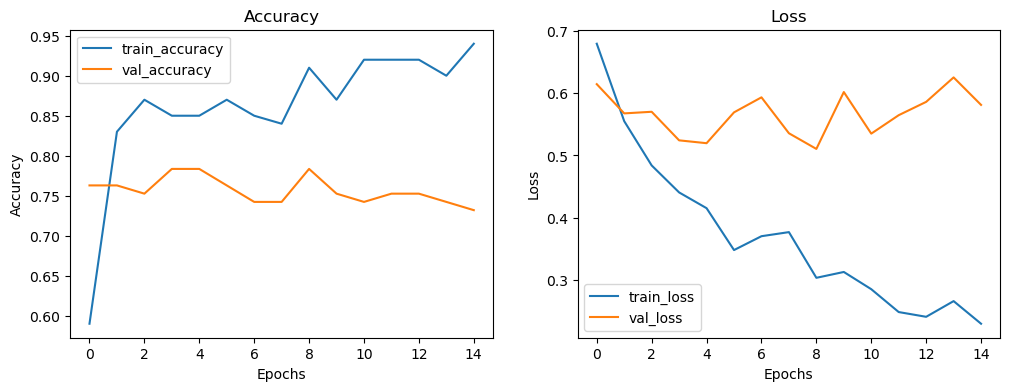

In [17]:
import matplotlib.pyplot as plt
# Plotting training and validation accuracy/loss
plt.figure(figsize=(12, 4))
 
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='train_accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.title('Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
 
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.title('Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
 
plt.show()

In [20]:
test_loss, test_acc = model.evaluate(test_data)
print(f'Test accuracy: {test_acc}')

/opt/anaconda3/lib/python3.12/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


 2/13 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.9375 - loss: 0.1965

/opt/anaconda3/lib/python3.12/site-packages/PIL/Image.py:3218: DecompressionBombWarning: Image size (89747104 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


 6/13 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.7951 - loss: 0.4003

/opt/anaconda3/lib/python3.12/site-packages/PIL/Image.py:3218: DecompressionBombWarning: Image size (104688771 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


13/13 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.7575 - loss: 0.5079
Test accuracy: 0.7319587469100952


In [21]:
train_loss, train_acc = model.evaluate(train_data)
print(f'Train accuracy: {train_acc}')

13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 979ms/step - accuracy: 0.9690 - loss: 0.1881
Train accuracy: 0.9399999976158142


In [23]:
base_model.trainable = True
 
# Freeze the first few layers
for layer in base_model.layers[:10]:
    layer.trainable = False
 
# Recompile the model with a lower learning rate
model.compile(optimizer=Adam(learning_rate=0.00001), loss='binary_crossentropy', metrics=['accuracy'])
 
# Continue training
history_fine = model.fit(
    train_data,
    epochs=30,
    validation_data=validation_data)

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 52s 3s/step - accuracy: 0.7933 - loss: 0.4499 - val_accuracy: 0.7423 - val_loss: 0.6298
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 40s 3s/step - accuracy: 0.8711 - loss: 0.3790 - val_accuracy: 0.7216 - val_loss: 0.6151
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 40s 3s/step - accuracy: 0.8896 - loss: 0.3377 - val_accuracy: 0.7423 - val_loss: 0.5910
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 40s 3s/step - accuracy: 0.8999 - loss: 0.2879 - val_accuracy: 0.7526 - val_loss: 0.6346
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 40s 3s/step - accuracy: 0.9057 - loss: 0.2587 - val_accuracy: 0.7732 - val_loss: 0.6343
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 40s 3s/step - accuracy: 0.9877 - loss: 0.1988 - val_accuracy: 0.7526 - val_loss: 0.6181
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 39s 3s/step - accuracy: 0.9012 - loss: 0.2879 - val_accuracy: 0.7423 - val_loss: 0.6285
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step - accuracy: 0.8364 - loss: 0.3570 - val_accuracy: 0.7629 - val_loss:

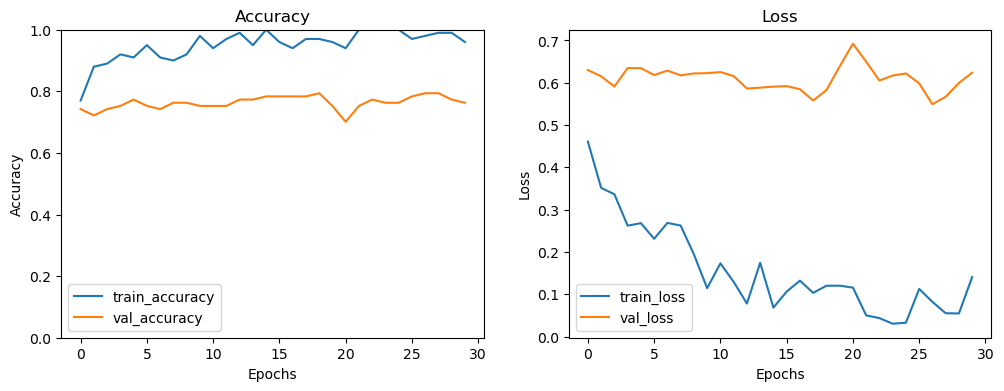

In [26]:
import matplotlib.pyplot as plt
# Plotting training and validation accuracy/loss
plt.figure(figsize=(12, 4))
 
plt.subplot(1, 2, 1)
plt.plot(history_fine.history['accuracy'], label='train_accuracy')
plt.plot(history_fine.history['val_accuracy'], label='val_accuracy')
plt.ylim([0,1])
plt.title('Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
 
plt.subplot(1, 2, 2)
plt.plot(history_fine.history['loss'], label='train_loss')
plt.plot(history_fine.history['val_loss'], label='val_loss')
plt.title('Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
 
plt.show()

In [28]:
train_loss, train_acc = model.evaluate(train_data)
print(f'Train accuracy: {train_acc}')

test_loss, test_acc = model.evaluate(test_data)
print(f'Test accuracy: {test_acc}')


13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 929ms/step - accuracy: 1.0000 - loss: 0.0051
Train accuracy: 1.0
13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.7902 - loss: 0.5627
Test accuracy: 0.7628865838050842
